# Phase 5 — Parallel Trip Research

**Objectives**:

- Delegate travel research to specialized agents.
- Execute independent research tasks in parallel.
- Combine specialist results for the main travel planner.

**How to implement it**:

1. An orchestrator LLM decides which specialist agents are needed and assigns each a self-contained research task.
2. The selected agents run in parallel using `Send`.
3. Each specialist is a subgraph with its own LLM and MCP tools, allowing multiple tool calls and retries within its domain.
4. Each subagent returns its research to the shared `TravelState`.
5. The main LLM combines the available specialist results and generates the response.

In [ ]:
# Imports and environment setup

import os
import json
import uuid
from typing import Annotated
from typing_extensions import TypedDict
from dotenv import load_dotenv
from IPython.display import Image, display, Markdown
from langchain_core.messages import SystemMessage, ToolMessage, HumanMessage, AIMessage
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langchain.tools import tool, ToolRuntime
from langgraph.types import Command, Send,  interrupt
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import InMemorySaver
from langchain_openrouter import ChatOpenRouter
from langchain_mcp_adapters.client import MultiServerMCPClient
from pydantic import BaseModel, Field
from datetime import datetime
from typing import Literal
from operator import add

load_dotenv(override=True)

True

## Code inherited from phase 4

### MCPs and tools

#### IMPORTANT: Adjustment for Windows

The following adjustment is needed when running MCP servers via stdio inside a Jupyter notebook on Windows. Jupyter's stderr stream is not a regular file, which can cause the MCP Python SDK to fail when launching the server. This workaround redirects the server's error output to DEVNULL. On macOS and Linux, no adjustment is required.

In [2]:
import sys

if sys.platform == "win32":
    import subprocess
    from functools import partial
    import langchain_mcp_adapters.sessions as mcp_sessions

    mcp_sessions.stdio_client = partial(mcp_sessions.stdio_client, errlog=subprocess.DEVNULL)
    print("Applied the Windows adjustment")
else:
    print("Not Windows, so nothing to do here")

Applied the Windows adjustment


In [3]:
mcp_client = MultiServerMCPClient({
        "ticketlens": {
            "transport": "http",
            "url": "https://mcp.ticketlens.com/",
        },
        # Alternative OpenMeteo MCP for testing weather tools
        # https://github.com/cyanheads/open-meteo-mcp-server
        "weather": {
            "transport": "streamable_http",
            "url": "https://open-meteo.caseyjhand.com/mcp",
        },
        "trvl": {
            "transport": "stdio",
            "command": "trvl",
            "args": ["mcp"],
        },
        "octotrip-rental-cars": {
            "transport": "http",
            "url": "https://mcp.octotrip.app/rental-cars/mcp",
        }
    }
)

tools = await mcp_client.get_tools()
print(f"Loaded {len(tools)} tools.")

weather_tools = []
ticketlens_tool_names = {"search_pois", "search_tours", "get_tour"}
ticketlens_tools = []
trvl_tool = None
rental_cars_tool = None

counter = 0

# Extract tools from each MCP
for t in tools:
    
    if t.name.startswith("openmeteo"):
        weather_tools.append(t)

    elif t.name in ticketlens_tool_names:
        ticketlens_tools.append(t)

    elif t.name == "travel":
        trvl_tool = t

    elif t.name == "search": 
        # Renamed to avoid conflicts with other MCPs
        t.name = "search_rental_cars"
        rental_cars_tool = t
    else:
        continue

    print(f"{t.name}: {t.description}")
    counter += 1

print(f"{counter} tools available for the agent.")

Loaded 18 tools.
search_tours: Search tour offers by query, POI, city, destination, price and tags
get_tour: Fetch canonical tour record by tour_id
search_pois: Resolve POI names, aliases, and possible candidates before tour search
openmeteo_search_locations: Resolve a place name to ranked coordinate matches with country, region, elevation, timezone, and population. Required prerequisite for name-based queries — all weather tools take latitude/longitude, not place names. Search by a bare place name (city, region, or landmark); never fold a qualifier into it — pass "Baoding", not "Baoding Hebei", and "Paris", not "Paris, France". To disambiguate places that share a name, set the country input (ISO 3166-1 alpha-2, e.g. "US") and/or read the admin1 and country fields on each ranked result — admin1 is a result field for choosing among matches, not a search input. Returns up to 10 matches ranked by population/relevance.
openmeteo_get_elevation: Terrain elevation from the Copernicus Digital 

In [ ]:
# New tool
@tool
def get_current_date() -> str:
    """Return the current date in YYYY-MM-DD format."""
    return datetime.now().strftime("%Y-%m-%d")

### Define the shared `TravelState`

In [5]:
# Define the shared TravelState
class TravelRequirements(BaseModel):
    origin: str | None = None
    destination: str | None = None
    travel_dates: str | None = None
    duration_days: int | None = None
    travelers: int | None = None
    budget: float | None = None
    currency: str | None = None
    interests: list[str] = Field(default_factory=list)
    constraints: list[str] = Field(default_factory=list)

class DestinationCandidate(BaseModel):
    destination: str
    score: float
    reason: str

class TravelState(TypedDict):
    messages: Annotated[list, add_messages]
    requirements: TravelRequirements | None
    
    destination_research_needed: bool 
    destination_candidates: list[DestinationCandidate]

#### Tool for updating the travel state

In [6]:
# Auxliary functions for update_requirements tool
def normalize_list(value: list[str] | str | None) -> list[str]:
    """
    Normalize a value into a list of strings.

    Accepts None, an existing list, or a JSON-encoded list returned as a string.
    If the string is not valid JSON, it is treated as a single list item.
    """
    if value is None:
        return []

    if isinstance(value, list):
        return value

    # The model may return the list as a JSON-encoded string.
    if isinstance(value, str):
        try:
            parsed = json.loads(value)

            # Return the parsed value if it is a valid JSON list.
            if isinstance(parsed, list):
                return parsed

        except json.JSONDecodeError:
            pass

        return [value]

    # Fallback for unexpected input types.
    return []

In [7]:
@tool
def update_requirements(
    runtime: ToolRuntime,
    origin: str | None = None,
    destination: str | None = None,
    travel_dates: str | None = None,
    duration_days: int | None = None,
    travelers: int | None = None,
    budget: float | None = None,
    currency: str | None = None,
    add_interests: list[str] | str | None = None,
    remove_interests: list[str] | str | None = None,
    add_constraints: list[str] | str | None = None,
    remove_constraints: list[str] | str | None = None,
) -> Command:
    """
    Update the user's current travel requirements.

    Only provide fields that have been explicitly added or changed by the user.

    For interests and constraints:
    - Use add_interests to add new interests.
    - Use remove_interests to remove previous interests.
    - Use add_constraints to add new constraints.
    - Use remove_constraints to remove previous constraints.

    Do not invent requirements or modify information that the user has not
    explicitly changed.
    """

    # ToolRuntime gives the tool access to the current LangGraph state,
    # including the TravelRequirements stored in the current graph execution.
    current = runtime.state["requirements"]

    if current is None:
        current = TravelRequirements()

    updated = current.model_copy()

    # Normalize list arguments in case the model sends JSON strings.
    add_interests = normalize_list(add_interests)
    remove_interests = normalize_list(remove_interests)
    add_constraints = normalize_list(add_constraints)
    remove_constraints = normalize_list(remove_constraints)

    # Update scalar fields only when explicitly provided
    if origin is not None:
        updated.origin = origin

    if destination is not None:
        updated.destination = destination

    if travel_dates is not None:
        updated.travel_dates = travel_dates

    if duration_days is not None:
        updated.duration_days = duration_days

    if travelers is not None:
        updated.travelers = travelers

    if budget is not None:
        updated.budget = budget

    if currency is not None:
        updated.currency = currency

    # Update interests
    if add_interests:
        updated.interests = list(
            dict.fromkeys(
                updated.interests + add_interests
            )
        )

    if remove_interests:
        updated.interests = [
            interest
            for interest in updated.interests
            if interest not in remove_interests
        ]

    # Update constraints
    if add_constraints:
        updated.constraints = list(
            dict.fromkeys(
                updated.constraints + add_constraints
            )
        )

    if remove_constraints:
        updated.constraints = [
            constraint
            for constraint in updated.constraints
            if constraint not in remove_constraints
        ]

    # Command tells LangGraph to update the graph state.
    # The new TravelRequirements replaces the current "requirements" value.
    return Command(
        update={
            "requirements": updated,
            "messages": [
                ToolMessage(
                    content="Travel requirements updated successfully.",
                    tool_call_id=runtime.tool_call_id,
                )
            ],
        }
    )

In [8]:
def sanitize_messages_for_llm(messages):
    """
    Auxiliary function for removing file/resource blocks from ToolMessages before 
    sending them to OpenAI Chat Completions.

    This fixes the error "OpenAI Chat Completions does not support file URLs." that 
    occured passing the trvl tool's response to the LLM.

    The original messages remain unchanged in LangGraph state.
    """

    sanitized = []

    for message in messages:

        if isinstance(message, ToolMessage) and isinstance(message.content, list):

            text_blocks = []

            for block in message.content:
                if (
                    isinstance(block, dict)
                    and block.get("type") == "text"
                    and "text" in block
                ):
                    text_blocks.append(block["text"])

            if text_blocks:
                sanitized.append(
                    ToolMessage(
                        content="\n".join(text_blocks),
                        tool_call_id=message.tool_call_id,
                        name=message.name,
                    )
                )

            else:
                sanitized.append(message)

        else:
            sanitized.append(message)

    return sanitized

### LLMs

In [9]:
# Providers that offer the best balance between speed and cost for MiMo-V2.5
# Xiaomi is preferred over NovitaAI because it is cheaper
MIMO_PROVIDER = {
    "order": ["xiaomi", "novita"],
    "allow_fallbacks": False,
}

# Normal LLM
llm = ChatOpenRouter(
    model="xiaomi/mimo-v2.5",
    api_key=os.environ["OPENROUTER_API_KEY"],
    openrouter_provider=MIMO_PROVIDER,
)

# Low-effort LLM for faster and cheaper responses
low_reasoning_llm = ChatOpenRouter(
    model="xiaomi/mimo-v2.5",
    api_key=os.environ["OPENROUTER_API_KEY"],
    openrouter_provider=MIMO_PROVIDER,
    reasoning={
        "effort": "minimal",
    },
)

# Lightweight LLM for simple tasks
light_llm = ChatOpenRouter(
    model="google/gemma-3-12b-it",
    api_key=os.getenv("OPENROUTER_API_KEY"),
)

### Requirements extraction node

This node is responsible for extracting user requirements and incorporating them into the graph state. In this case, we use the same LLM as in the previous phases, but we now **reduce its reasoning effort** to obtain faster and more cost-effective responses.

In [10]:
REQUIREMENTS_EXTRACTION_PROMPT = """
Extract the user's explicit travel requirements into the provided schema.

Only include information explicitly stated by the user.
Do not infer preferences, constraints, destinations, dates, budgets, or other values.

Preserve the user's meaning when normalizing values such as dates and currency.
Leave unknown fields empty.
"""

In [11]:
requirements_llm = low_reasoning_llm.with_structured_output(
    TravelRequirements
)

async def extract_requirements(state: TravelState):
    response = await requirements_llm.ainvoke([
        SystemMessage(content=REQUIREMENTS_EXTRACTION_PROMPT),
        *sanitize_messages_for_llm(state["messages"]),
    ])

    return {"requirements": response}

### Research router

The router is implemented as an LLM call that returns only whether or not destination search mode should be enabled. Since the task is simple in this case, a **lighter model** is used to reduce costs and improve response time.

In [12]:
class ResearchDecision(BaseModel):
    needs_research: bool

In [13]:
RESEARCH_ROUTER_PROMPT = """
You are a travel-planning router.

Decide whether destination research is needed.

Set needs_research=true when the user has not committed to a single destination
and would benefit from discovering, comparing, or selecting destinations.
This includes requests that provide multiple destinations and ask to compare
or choose between them.

Set needs_research=false only when the user has clearly chosen one specific
destination, even if they want to research hotels, flights, activities, or
other options there.

Base the decision only on the user's request. Do not invent requirements.
"""

In [14]:
structured_router_llm = light_llm.with_structured_output(ResearchDecision)

async def research_router(state: TravelState):
    response = await structured_router_llm.ainvoke([
        SystemMessage(content=RESEARCH_ROUTER_PROMPT),
        *sanitize_messages_for_llm(state["messages"]),
    ])

    return {"destination_research_needed": response.needs_research}

### Destination research node

In [15]:
class DestinationResearchResult(BaseModel):
    candidates: list[DestinationCandidate]

In [16]:
DESTINATION_RESEARCH_PROMPT = """
You are the destination discovery step of a travel planner.

Generate 3-5 diverse destinations that best match the user's explicit
requirements. Score and order them from best to worst fit.

For each candidate provide:
- destination
- score from 0 to 10 (one decimal allowed)
- reason: a short overview of the destination followed by brief points
  explaining how it matches the user's main requirements.

Score how well the destination matches the user's requirements, not how
popular or attractive it is in general.

Use only explicit requirements. Do not invent preferences.

General, non-time-specific facts about climate, relative affordability,
culture, food, etc. are allowed. Do not provide specific prices,
availability, or other precise future-dependent facts.
"""

In [17]:
destination_llm = llm.with_structured_output(DestinationResearchResult)

async def destination_research(state: TravelState):
    # DEBUG 
    print("Running destination research...")

    requirements = state["requirements"]

    response = await destination_llm.ainvoke([
        SystemMessage(content=DESTINATION_RESEARCH_PROMPT),
        SystemMessage(content=f"Current travel requirements:\n{requirements}"),
        *sanitize_messages_for_llm(state["messages"]),
    ])

    return {
        "destination_candidates": response.candidates
    }

In [18]:
def display_destination_results(state: TravelState):
    destinations = state["destination_candidates"]

    print("\n" + "=" * 60)
    print("DESTINATION RECOMMENDATIONS")
    print("=" * 60)

    for i, candidate in enumerate(destinations, 1):
        print(f"\n{i}. {candidate.destination} — {candidate.score:.1f}/10")
        print(f"   {candidate.reason}")

    return {
        # Provide context to the next LLM call that destination research has been completed
        "messages": [
            SystemMessage(
                content=(
                    "Destination research has been completed and the recommendations "
                    "were presented to the user. The next user message is a response "
                    "to those recommendations and may select or modify a destination."
                )
            )
        ]
    }

In [19]:
def wait_for_decision(state: TravelState):
    user_input = interrupt("Choose a destination or provide another preference.")

    return {
        "messages": [
            HumanMessage(content=user_input)
        ]
    }

## New multi-agent orchestration system

In [20]:
class AgentTask(BaseModel):
    agent: Literal[
        "weather_agent",
        "accommodation_agent",
        "transportation_agent",
        "activities_agent",
        "rental_cars_agent",
    ]
    task: str

class OrchestrationPlan(BaseModel):
    tasks: list[AgentTask]

In [21]:
class TravelState(TypedDict):
    messages: Annotated[list, add_messages]
    requirements: TravelRequirements | None
    
    destination_research_needed: bool 
    destination_candidates: list[DestinationCandidate]

    # NEW: Results from each sub-agent
    orchestration_plan: list[AgentTask]

    weather_results: Annotated[list, add]
    accommodation_results: Annotated[list, add]
    transportation_results: Annotated[list, add]
    activity_results: Annotated[list, add]
    rental_car_results: Annotated[list, add]

In [22]:
class SubagentState(TypedDict):
    task: str
    messages: Annotated[list, add_messages]
    result: str | None

In [23]:
# These are faster and cheaper options but they are usually blocked in OpenRouter 
# because they have a higher demand. As a fallback, we use MiMo-V2.5 with minimal reasoning.
# subagent_llm = ChatOpenAI(
#     model="inclusionai/ling-3.0-flash",
#     # model="mistralai/mistral-small-3.2-24b-instruct",
#     # model="google/gemma-3-27b-it",
#     base_url="https://openrouter.ai/api/v1",
#     api_key=os.getenv("OPENROUTER_API_KEY"),
# )
subagent_llm = low_reasoning_llm

### Weather sub-agent

In [24]:
WEATHER_AGENT_PROMPT = """
You are the weather research specialist in a travel-planning system.

Complete the research task using the available weather tools.

Use the user's requirements and the task provided by the orchestrator.
Choose the appropriate weather tools and provide all required parameters.
You may make multiple tool calls when necessary.

Use forecast data when it is appropriate for the travel dates and historical
climate data when it helps describe typical conditions.

Avoid retrieving large raw datasets when a smaller query, summary, or aggregate
can answer the task. Do not request multi-year daily historical data unless it
is necessary. When historical data is useful, retrieve only the minimum period,
locations, and variables needed.

Prefer aggregated, summarized, or directly relevant weather information over
large collections of individual daily records.

Do not research other travel categories.

Output:
- Present the most relevant weather findings clearly and concisely.
- When comparing several periods, locations, or weather conditions, use a table
  when it improves clarity; otherwise organize the information into short sections.
- Report only the most relevant findings and include a short summary of any
  remaining results rather than listing everything.
- Distinguish forecast data, historical climate patterns, and uncertainty.
- Preserve dates and values exactly as returned by the tools.
- Do not invent specific weather conditions, forecasts, or climate statistics.
- End with a brief "Key findings" section for the main travel planner.
"""

In [25]:
weather_llm = subagent_llm.bind_tools(weather_tools)

async def weather_agent(state: SubagentState):
    task = state["task"]

    response = await weather_llm.ainvoke([
        SystemMessage(content=WEATHER_AGENT_PROMPT),
        SystemMessage(content=f"Assigned task:\n{task}"),
        *sanitize_messages_for_llm(state["messages"]),
    ])

    return {"messages": [response]}

### Accommodation sub-agent

In [26]:
ACCOMMODATION_AGENT_PROMPT = """
You are the accommodation research specialist in a travel-planning system.

Complete the assigned task using the TRVL travel tool.

For accommodation searches, always try search_accommodations first.
Use search_hotels only as a fallback when search_accommodations cannot satisfy
the task or when broad hotel discovery is explicitly requested.

For search_accommodations, provide all known required parameters explicitly:
location, check_in, check_out, guests, currency, and budget when available.
Use max_candidates=5 and max_offers=5 unless broader results are explicitly requested.

Use relevant filters when they match the task and are supported by the tool.

If the tool returns an error caused by incorrect arguments, correct them and retry.
Do not invent prices, availability, ratings, or other missing information.

Output:
- Report only the 3-5 most relevant accommodation offers with their key
  factual details and a short summary of the remaining results.
- When comparing several properties, use a table whenever practical.
- For each selected offer, clearly identify property, room, price, total price,
  taxes, cancellation/refundability, rating, and booking information when available.
- Clearly distinguish verified prices from lead-in, estimated, or unverified prices.
- Preserve tool-returned values exactly.
- Do not add property or neighborhood facts that were not returned by the tool.
- End with a brief "Key findings" section for the main travel planner.

Do not research flights, ground transport, weather, activities, or rental cars.
"""

In [27]:
accommodation_llm = subagent_llm.bind_tools([trvl_tool])

async def accommodation_agent(state: SubagentState):
    task = state["task"]

    response = await accommodation_llm.ainvoke([
        SystemMessage(content=ACCOMMODATION_AGENT_PROMPT),
        SystemMessage(content=f"Assigned task:\n{task}"),
        *sanitize_messages_for_llm(state["messages"]),
    ])

    return {"messages": [response]}

### Transportation sub-agent

In [28]:
TRANSPORTATION_AGENT_PROMPT = """
You are the transportation research specialist in a travel-planning system.

Complete the assigned task using the TRVL travel tool.

Use only transportation intents:
- search_flights for air travel.
- search_ground for trains, buses, and ferries.

For flights, use origin, destination, departure_date, and passengers when known.
For round trips, also provide return_date.

Use relevant filters when explicitly requested, such as cabin_class, max_stops,
max_price, max_duration, airlines, departure-time windows, or baggage requirements.

For ground transport, use from, to, date, and type when known.
type must be exactly one of: train, bus, ferry.

Use relevant ground filters when requested.

If the tool returns an error caused by incorrect arguments, correct the parameters
and retry. Do not invent prices, schedules, availability, or missing information.

Output:
- Report only the 3-5 most relevant transport options with their key factual
  details and a short summary of the remaining results.
- When comparing several options, use a table whenever practical.
- Clearly separate flights, trains, buses, and ferries when multiple modes are found.
- For each option, clearly identify price, duration, stops, times, and provider
  when available.
- Distinguish per-person prices from total prices.
- Preserve tool-returned values exactly and state uncertainty where present.
- End with a brief "Key findings" section for the main travel planner.

Do not research accommodations, weather, activities, or rental cars.
"""

In [29]:
transportation_llm = subagent_llm.bind_tools([trvl_tool])

async def transportation_agent(state: SubagentState):
    task = state["task"]

    response = await transportation_llm.ainvoke([
        SystemMessage(content=TRANSPORTATION_AGENT_PROMPT),
        SystemMessage(content=f"Assigned task:\n{task}"),
        *sanitize_messages_for_llm(state["messages"]),
    ])

    return {"messages": [response]}

### Activities sub-agent

In [30]:
ACTIVITIES_AGENT_PROMPT = """
You are the activities and experiences research specialist.

Complete the assigned research task using the available TicketLens tools.

Search for activities, attractions, tours, and experiences relevant to the
destination, travel dates, and user's interests.

Use multiple tool calls when useful and retrieve additional details when the
task requires them.

Do not research flights, accommodations, weather, or rental cars.

Output:
- Report only the 3-5 most relevant activities with their key factual details
  and a short summary of the remaining results.
- When comparing several activities, use a table whenever practical; otherwise
  organize them into short sections.
- For each activity, include its name, type, location, price, availability,
  rating, and booking information when returned by the tools.
- Distinguish confirmed tool data from missing or uncertain information.
- Do not invent opening times, prices, availability, or activity details.
- End with a brief "Key findings" section for the main travel planner.
"""

In [31]:
activities_llm = subagent_llm.bind_tools(ticketlens_tools)

async def activities_agent(state: SubagentState):
    task = state["task"]

    response = await activities_llm.ainvoke([
        SystemMessage(content=ACTIVITIES_AGENT_PROMPT),
        SystemMessage(content=f"Assigned task:\n{task}"),
        *sanitize_messages_for_llm(state["messages"]),
    ])

    return {"messages": [response]}

### Rental cars sub-agent

In [32]:
RENTAL_CARS_AGENT_PROMPT = """
You are the rental-car research specialist.

Complete the assigned research task using the available rental-car tools.

Choose the appropriate tool and parameters based on the task.
Consider vehicle preferences, dates, pickup/dropoff location, passengers,
budget, and other explicitly stated constraints.

You may make multiple searches when necessary.
If a tool returns an error caused by incorrect arguments, correct the parameters
and retry.

Do not invent prices, vehicle availability, specifications, or missing information.

Output:
- Report only the 3-5 most relevant rental options with their key factual
  details and a short summary of the remaining results.
- When comparing several vehicles or rental options, use a table whenever practical.
- Clearly identify vehicle, rental period, pickup/dropoff location, price,
  rental conditions, and booking information when available.
- Preserve tool-returned values exactly.
- Distinguish verified prices from estimates or incomplete results.
- End with a brief "Key findings" section for the main travel planner.

Do not research flights, accommodations, weather, or activities.
"""

In [33]:
rental_cars_llm = subagent_llm.bind_tools([rental_cars_tool])

async def rental_cars_agent(state: SubagentState):
    task = state["task"]

    response = await rental_cars_llm.ainvoke([
        SystemMessage(content=RENTAL_CARS_AGENT_PROMPT),
        SystemMessage(content=f"Assigned task:\n{task}"),
        *sanitize_messages_for_llm(state["messages"]),
    ])

    return {"messages": [response]}

### Orchestrator

In [34]:
ORCHESTRATOR_PROMPT = """
You are the travel research orchestrator.

Based on the user's latest request and current travel requirements, decide
which specialist agents are needed to provide the requested information.

Available agents:
- weather_agent: weather and climate information
- accommodation_agent: hotels and other accommodation options
- transportation_agent: flights, trains, buses, and ferries
- activities_agent: attractions, activities, tours, and experiences
- rental_cars_agent: rental car options

Only activate agents relevant to the user's request.

For each selected agent, write a clear task describing exactly what it should
research, using the user's requirements as context. 

Each task must be self-contained: include all information the specialist
needs to perform its research without accessing the main conversation state.
Do not omit known dates, locations, travelers, budget, or relevant constraints.

Do not perform research yourself and do not invent requirements.
"""

In [35]:
orchestrator_llm = llm.with_structured_output(OrchestrationPlan)

async def orchestrator(state: TravelState):
    requirements = state["requirements"]

    response = await orchestrator_llm.ainvoke([
        SystemMessage(content=ORCHESTRATOR_PROMPT),
        SystemMessage(
            content=f"Current travel requirements:\n{requirements}"
        ),
        *sanitize_messages_for_llm(state["messages"]),
    ])

    return {
        "orchestration_plan": response.tasks
    }

### Main LLM

In [36]:
MAIN_LLM_PROMPT = """
You are a Travel Planner specialized in personalized trip planning.
Help users make informed decisions based on their requirements.

Behavior:
- Be helpful, practical, clear, and honest about uncertainty.
- Prioritize explicit user requirements and ask when essential information is missing.
- Do not invent facts, prices, availability, or other real-world data.
- Explain important recommendations and avoid generic suggestions.

Destination research:
- Treat previously presented destination candidates as suggestions, not as a decision.
- If the user selects or specifies a destination, use update_requirements to save it
  and continue planning for that destination.

Requirements:
- Treat current requirements as the trip's current state.
- Use update_requirements when the user adds, changes, removes, or reverses a requirement.
- Only update explicitly provided information; preserve unchanged requirements.
- When requirements conflict, follow the latest explicit instruction.

Research results:
- Use specialist research results as the primary source for researched facts.
- Combine results from different specialists when comparing travel options.
- Preserve prices, dates, ratings, availability, and confidence information as returned.
- Do not turn estimated, lead-in, or unverified data into confirmed facts.
- Do not repeat research that has already been completed unless the user requests
  updated or different information.
- Clearly distinguish researched data from general knowledge.
- When research is incomplete or unavailable, state the limitation.

Conversation:
- When the user only selects a destination, save it and ask what they would like
  to research next rather than starting unrelated searches.
- Ask for missing information when it is necessary for a specific search.
- Do not assume a transport mode if the user has not chosen one.

Scope:
- Only answer questions related to travel planning and your capabilities.
- If the user asks about something outside your scope, briefly explain that you cannot help with it.
"""

In [37]:
main_tools = [update_requirements]
main_llm = llm.bind_tools(main_tools)

async def main_llm_node(state: TravelState) -> dict:
    # Extract results from each sub-agent and format them for the main LLM.
    subagents_results = []

    if state.get("weather_results"):
        subagents_results.append(
            f"Weather research:\n{state['weather_results']}"
        )

    if state.get("accommodation_results"):
        subagents_results.append(
            f"Accommodation research:\n{state['accommodation_results']}"
        )

    if state.get("transportation_results"):
        subagents_results.append(
            f"Transportation research:\n{state['transportation_results']}"
        )

    if state.get("activity_results"):
        subagents_results.append(
            f"Activities research:\n{state['activity_results']}"
        )

    if state.get("rental_car_results"):
        subagents_results.append(
            f"Rental car research:\n{state['rental_car_results']}"
        )

    # The LLM receives system prompt + requirements +...
    messages = [
        SystemMessage(content=MAIN_LLM_PROMPT),
        SystemMessage(
            content=f"Current travel requirements:\n{state['requirements']}"
        ),
    ]

    # ...+ subagents' research results (if any) +...
    if subagents_results:
        messages.append(
            SystemMessage(
                content="Research results from specialist agents:\n\n"
                + "\n\n".join(subagents_results)
            )
        )

    # ...+ the conversation history.
    messages.extend(state["messages"])

    response = await main_llm.ainvoke(messages)

    return {"messages": [response]}

## Build the new graph

In [38]:
# Destination research router associated with the router node
def route_destination_research(state: TravelState):
    if state["destination_research_needed"]:
        return "destination_research"
    return "orchestrator"

In [39]:
# Agents router associated with the orchestrator
def route_to_agents(state: TravelState):
    return [
        Send(
            task.agent,
            {
                "task": task.task,
                "messages": [],
                "result": None,
            }
        )
        for task in state["orchestration_plan"]
    ]

In [40]:
# Helper for building each subagent's graph
def build_subagent_graph(agent_node, tool_node):
    graph_builder = StateGraph(SubagentState)

    graph_builder.add_node("agent", agent_node)
    graph_builder.add_node("tools", tool_node)
    graph_builder.add_node("finalize", finalize_subagent)

    graph_builder.add_edge(START, "agent")
    graph_builder.add_conditional_edges(
        "agent",
        tools_condition,
        {
            "tools": "tools",
            END: "finalize",
        },
    )
    graph_builder.add_edge("tools", "agent")
    graph_builder.add_edge("finalize", END)

    return graph_builder.compile()

# Helper for storing the subagent's response into the main graph's state
def finalize_subagent(state: SubagentState):
    return {
        "result": state["messages"][-1].content
    }

In [41]:
# ---- Subgraphs ----
weather_graph = build_subagent_graph(
    weather_agent, 
    ToolNode(weather_tools)
)
async def run_weather_agent(state: TravelState):
    # Wrapper used to map the subagent's private state/output to the main TravelState.
    result = await weather_graph.ainvoke({
        "task": state["task"],
        "messages": [],
        "result": None,
    })

    return {
        "weather_results": [result["result"]]
    }

accommodation_graph = build_subagent_graph(
    accommodation_agent,
    ToolNode([trvl_tool])
)
async def run_accommodation_agent(state: TravelState):
    result = await accommodation_graph.ainvoke({
        "task": state["task"],
        "messages": [],
        "result": None,
    })

    return {
        "accommodation_results": [result["result"]]
    }

transportation_graph = build_subagent_graph(
    transportation_agent,
    ToolNode([trvl_tool])
)
async def run_transportation_agent(state: TravelState):
    result = await transportation_graph.ainvoke({
        "task": state["task"],
        "messages": [],
        "result": None,
    })

    return {
        "transportation_results": [result["result"]]
    }

activities_graph = build_subagent_graph(
    activities_agent,
    ToolNode(ticketlens_tools)
)
async def run_activities_agent(state: TravelState):
    result = await activities_graph.ainvoke({
        "task": state["task"],
        "messages": [],
        "result": None,
    })

    return {
        "activity_results": [result["result"]]
    }

rental_cars_graph = build_subagent_graph(
    rental_cars_agent,
    ToolNode([rental_cars_tool])
)
async def run_rental_cars_agent(state: TravelState):
    result = await rental_cars_graph.ainvoke({
        "task": state["task"],
        "messages": [],
        "result": None,
    })

    return {
        "rental_car_results": [result["result"]]
    }

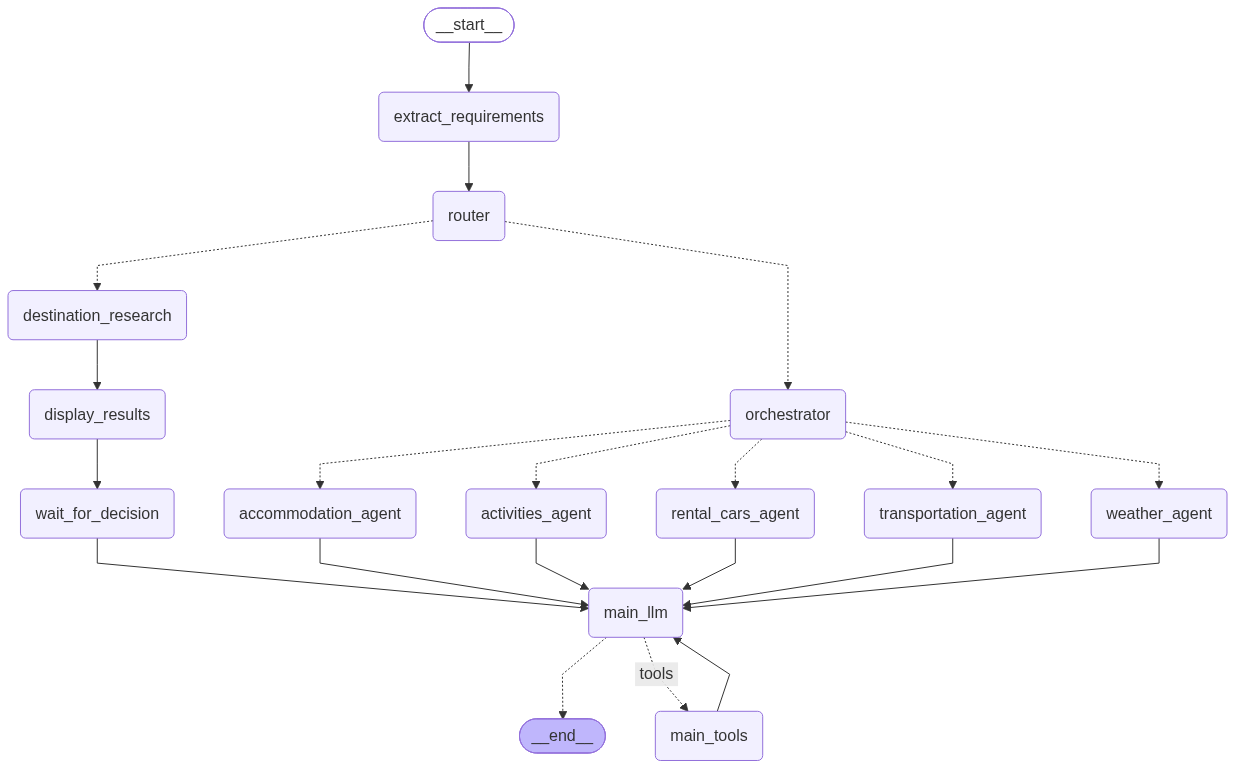

In [46]:
# Add short-term memory checkpointing
checkpointer = InMemorySaver()

builder = StateGraph(TravelState)

# ---- Nodes ----
builder.add_node("extract_requirements", extract_requirements)
builder.add_node("router", research_router)

builder.add_node("destination_research", destination_research)
builder.add_node("display_results", display_destination_results)
builder.add_node("wait_for_decision", wait_for_decision)

# Subagents
weather_graph = build_subagent_graph(weather_agent, ToolNode(weather_tools))
accommodation_graph = build_subagent_graph(accommodation_agent, ToolNode([trvl_tool]))
transportation_graph = build_subagent_graph(transportation_agent, ToolNode([trvl_tool]))
activities_graph = build_subagent_graph(activities_agent, ToolNode(ticketlens_tools))
rental_cars_graph = build_subagent_graph(rental_cars_agent, ToolNode([rental_cars_tool]))

# Parallel multi-agent orchestration
builder.add_node("orchestrator", orchestrator)
builder.add_node("weather_agent", run_weather_agent)
builder.add_node("accommodation_agent", run_accommodation_agent)
builder.add_node("transportation_agent", run_transportation_agent)
builder.add_node("activities_agent", run_activities_agent)
builder.add_node("rental_cars_agent", run_rental_cars_agent)
builder.add_node("main_llm", main_llm_node)
builder.add_node("main_tools", ToolNode(main_tools))

# ---- Edges ----
builder.add_edge(START, "extract_requirements")
builder.add_edge("extract_requirements", "router")

builder.add_conditional_edges(
    "router",
    route_destination_research,
    {
        "destination_research": "destination_research",
        "orchestrator": "orchestrator",
    },
)

builder.add_edge("destination_research", "display_results")
builder.add_edge("display_results", "wait_for_decision")
builder.add_edge("wait_for_decision", "main_llm")

# New edges for parallel multi-agent orchestration
builder.add_conditional_edges(
    "orchestrator",
    route_to_agents,
    [
        "weather_agent",
        "accommodation_agent",
        "transportation_agent",
        "activities_agent",
        "rental_cars_agent",
    ],
)
# Bind agents to main LLM
builder.add_edge("weather_agent", "main_llm")
builder.add_edge("accommodation_agent", "main_llm")
builder.add_edge("transportation_agent", "main_llm")
builder.add_edge("activities_agent", "main_llm")
builder.add_edge("rental_cars_agent", "main_llm")
builder.add_conditional_edges(
    "main_llm",
    tools_condition,
    {
        "tools": "main_tools",
        END: END,
    },
)
builder.add_edge("main_tools", "main_llm")

# ---- Compile ----
graph = builder.compile(checkpointer=checkpointer)

display(Image(graph.get_graph().draw_mermaid_png()))

## Test with different prompts

In [95]:
async def test_travel(prompt: str):
    thread_id = str(uuid.uuid4())
    config = {"configurable": {"thread_id": thread_id}}

    print("=" * 80)
    print(f"USER: {prompt}")
    print("=" * 80)

    # First execution
    result = await graph.ainvoke(
        {
            "messages": [HumanMessage(content=prompt)],
            "requirements": None,
        },
        config=config,
    )

    # If the graph stopped at wait_for_decision
    state = await graph.aget_state(config)

    if state.next:
        print(f"\nGraph paused at: {state.next}")

        if "wait_for_decision" in state.next:
            user_input = input("\nChoose a destination (or type your preference): ")

            # Resume the same graph execution
            result = await graph.ainvoke(
                Command(resume=user_input),
                config=config,
            )

    print("\n" + "=" * 80)
    print("FINAL STATE")
    print("=" * 80)

    final_state = await graph.aget_state(config)

    print("Requirements:")
    print(final_state.values.get("requirements"))

    print("\nMessages:")
    for msg in final_state.values.get("messages", []):
        if msg.content:
            print(f"{msg.type.upper()}: {msg.content}")

**Important**: After every test, verify the agent's traces with [LangSmith](https://smith.langchain.com) for ensuring that the agent is following the correct steps and interacting with the tools correctly.

In [ ]:
# Flight + accommodation
test1 = "I'm planning a trip to Paris from Madrid for two people, from September 10 " \
    "to September 14, 2026. Search for suitable round-trip flights and accommodations. "
await test_travel(test1)

USER: I'm planning a trip to Paris from Madrid for two people, from September 10 to September 14, 2026. Search for suitable round-trip flights and accommodations. 


Deserializing unregistered type __main__.TravelRequirements from checkpoint. This will be blocked in a future version. Set LANGGRAPH_STRICT_MSGPACK=true to block now, or add to allowed_msgpack_modules to allow explicitly: [('__main__', 'TravelRequirements')]
Deserializing unregistered type __main__.AgentTask from checkpoint. This will be blocked in a future version. Set LANGGRAPH_STRICT_MSGPACK=true to block now, or add to allowed_msgpack_modules to allow explicitly: [('__main__', 'AgentTask')]



FINAL STATE
Requirements:
origin='Madrid' destination='Paris' travel_dates='September 10 - September 14, 2026' duration_days=None travelers=2 budget=None currency=None interests=[] constraints=[]

Messages:
HUMAN: I'm planning a trip to Paris from Madrid for two people, from September 10 to September 14, 2026. Search for suitable round-trip flights and accommodations. 
AI: I have the research results for your Paris trip (September 10-14, 2026, 2 passengers). Here's what I found:

---

## ✈️ Flights: Madrid → Paris

| Option | Airline | Outbound | Return | Stops | Price (2 pax) |
|--------|---------|----------|--------|-------|---------------|
| **Best Value (Nonstop)** | Air France + Iberia | 12:20–14:25 | 18:50–21:00 | Nonstop both ways | **€258** |
| **Budget Option** | Transavia France | 06:00–08:05 | 18:30–01:05+1 | Nonstop out / 1 stop return | **€246** |
| **Morning Flights** | Air France | 10:05–12:10 | 09:15–11:20 | Nonstop both ways | **€266** |

**My recommendation:** The Ai

In [ ]:
# Accommodation + activities
test2 = "I'm going to Rome from Barcelona for three people, from October 5 " \
    "to October 12, 2026. Find accommodation and some interesting activities " \
    "for us. We have a budget of €1,500."
await test_travel(test2)

USER: I'm going to Rome from Barcelona for three people, from October 5 to October 12, 2026. Find accommodation and some interesting activities for us. We have a budget of €1,500.

FINAL STATE
Requirements:
origin='Barcelona' destination='Rome' travel_dates='October 5 to October 12, 2026' duration_days=7 travelers=3 budget=1500.0 currency='EUR' interests=[] constraints=[]

Messages:
HUMAN: I'm going to Rome from Barcelona for three people, from October 5 to October 12, 2026. Find accommodation and some interesting activities for us. We have a budget of €1,500.
AI: Great news! I found excellent options for both accommodation and activities in Rome for your group of 3. Here's what I discovered:

---

## 🏨 Accommodation Options (7 nights, October 5–12, 2026)

| Property | Type | Rating | Total Price | Cancellation |
|----------|------|--------|-------------|--------------|
| **Fabulous Village** | Villa/Camping Village | ⭐ 4.1 (16,777 reviews) | **€471.24** | Non-refundable |
| **hu Roma 

In [ ]:
# Flights + accommodation + rental car
test3 = "I want to visit Lisbon for one week in September 2026 with my partner. " \
    "We are interested in good weather, food and cultural activities. " \
    "Please find flights from Madrid, a suitable hotel, and a rental car."
await test_travel(test3)

USER: I want to visit Lisbon for one week in September 2026 with my partner. We are interested in good weather, food and cultural activities. Please find flights from Madrid, a suitable hotel, and a rental car.

FINAL STATE
Requirements:
origin='Madrid' destination='Lisbon' travel_dates='September 2026' duration_days=7 travelers=2 budget=None currency=None interests=['good weather', 'food', 'cultural activities'] constraints=[]

Messages:
HUMAN: I want to visit Lisbon for one week in September 2026 with my partner. We are interested in good weather, food and cultural activities. Please find flights from Madrid, a suitable hotel, and a rental car.
AI: I've already researched flights, hotels, and rental cars for your Lisbon trip! Let me compile the findings based on your interests in food, culture, and good weather.

---

## ✈️ Flights: Madrid (MAD) → Lisbon (LIS)

Great news! All flights are **nonstop** with a short flight time of about **1.5 hours**.

| Option | Airlines | Departure | 

In [97]:
# Weather + flights + accommodation + rental car + activities
test4 = "I want to visit Lisbon for one week in September 2026 with my partner. " \
    "We are interested in good weather, food and cultural activities. " \
    "Please find trains or flights from Madrid, a suitable hotel, a rental car, " \
    " and some activities. Also provide a summary of the expected weather during our stay."
await test_travel(test4)

USER: I want to visit Lisbon for one week in September 2026 with my partner. We are interested in good weather, food and cultural activities. Please find trains or flights from Madrid, a suitable hotel, a rental car,  and some activities. Also provide a summary of the expected weather during our stay.

FINAL STATE
Requirements:
origin='Madrid' destination='Lisbon' travel_dates='September 2026' duration_days=7 travelers=2 budget=None currency=None interests=['good weather', 'food', 'cultural activities'] constraints=[]

Messages:
HUMAN: I want to visit Lisbon for one week in September 2026 with my partner. We are interested in good weather, food and cultural activities. Please find trains or flights from Madrid, a suitable hotel, a rental car,  and some activities. Also provide a summary of the expected weather during our stay.
AI: # Lisbon Trip Plan: September 2026 (1 Week for 2)

Based on your interests in good weather, food, and cultural activities, and after reviewing specialist res